# Demo: how the evaluation file `all_projects_clean.csv` is built

This notebook shows, step by step, how the evaluation file is built from the prepared datasets.

**The whole path (4 steps):**
1. `data/raw/`: the public datasets that were downloaded (requirements, code, expert answer keys).
2. `load_dataset.ipynb`: converts them into `data/processed/`.
3. **This notebook shows:** `build_gold_pairs.py`. It takes every labelled pair, cleans the code, and writes a CSV.
4. The final file: `data/final/all_projects_clean.csv`, which is used for the evaluation.

The notebook needs no internet, no Neo4j and no LLM. Run the cells from top to bottom.

## 1. Setup

Finds the project folder and imports the script. `build_gold_pairs` is the script that builds the file; this notebook does not change it.

In [1]:
import os, sys, json, csv
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'agents').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import scripts.build_gold_pairs as bgp
csv.field_size_limit(sys.maxsize)
print('project folder:', ROOT)

project folder: /Users/habbglobal/Desktop/J26-SE-327/project


## 2. Input: the prepared datasets

Each project has one folder with two files: `artifacts.json` (the requirement and code texts) and `gold.json` (the list of labels that say which requirement is linked to which code). The next cell counts the labelled pairs and the true links of each project.

In [2]:
for folder in sorted(p for p in (ROOT / 'data' / 'processed').iterdir() if (p / 'gold.json').exists()):   # folders without answer keys are skipped
    gold = json.loads((folder / 'gold.json').read_text(encoding='utf-8'))
    arts = json.loads((folder / 'artifacts.json').read_text(encoding='utf-8'))
    true = sum(1 for _, _, t in gold if t)
    print(f"{folder.name:8s} artifacts {len(arts):5d}   labelled pairs {len(gold):6d}   true links {true:5d}")

cm1      artifacts    75   labelled pairs   1166   true links    45
eanci    artifacts    94   labelled pairs   2145   true links   567
ebt      artifacts    91   labelled pairs   2050   true links    98
etour    artifacts   174   labelled pairs   6728   true links   308
itrust   artifacts   523   labelled pairs  51352   true links   399
libest   artifacts    66   labelled pairs    728   true links   204
smos     artifacts   167   labelled pairs   6700   true links  1044


### What does one labelled pair look like?

Each line of `gold.json` is `[requirement_id, code_id, is_true]`. Below are the first five lines of iTrust.

In [3]:
gold = json.loads((ROOT / 'data' / 'processed' / 'itrust' / 'gold.json').read_text(encoding='utf-8'))
for r in gold[:5]: print(r)

['UC10E1', 'AccessDAO', False]
['UC10E1', 'AddApptAction', False]
['UC10E1', 'AddERespAction', False]
['UC10E1', 'AddHCPAction', False]
['UC10E1', 'AddOfficeVisitAction', False]


## 3. Step A: all labelled pairs go into `all_projects.csv`

This step takes every labelled pair, reads the requirement text and the code text, and writes one row per pair. The rules:
* A pair without a label is not taken, so every row has a real answer.
* If an artifact is missing, or its text is empty, the pair is dropped.
* The same (project, requirement, code) appearing twice is kept once.
* Every run of spaces and line breaks in a text becomes one single space.

In [4]:
import tempfile
WORK = Path(tempfile.mkdtemp(prefix='gold_demo_'))          # the demo writes to a temporary folder, never over data/final
a_path, report_a = bgp.step_a(WORK)
print('written (temporary):', a_path)
print('report:', json.dumps({k: v for k, v in report_a.items() if k != 'projects'}, indent=1))
print('per project:', json.dumps(report_a['projects'], indent=1))

written (temporary): /var/folders/bz/0k4cpp4s41b3_t3zdw6jp6s00000gn/T/gold_demo_pjbuiyjt/all_projects.csv
report: {
 "dropped": {
  "folder_without_gold": 1
 },
 "total_pairs": 70869,
 "total_positives": 2665
}
per project: {
 "cm1": {
  "pairs": 1166,
  "positives": 45
 },
 "eanci": {
  "pairs": 2145,
  "positives": 567
 },
 "ebt": {
  "pairs": 2050,
  "positives": 98
 },
 "etour": {
  "pairs": 6728,
  "positives": 308
 },
 "itrust": {
  "pairs": 51352,
  "positives": 399
 },
 "libest": {
  "pairs": 728,
  "positives": 204
 },
 "smos": {
  "pairs": 6700,
  "positives": 1044
 }
}


## 4. Step B: clean the code into `all_projects_clean.csv`

Now the code text is cleaned. The `package` and `import` lines at the top of a Java file carry no meaning about what the code does, so they are removed. In addition:
* **Targets that are not code** (design documents in CM-1, manifest files in iTrust) are dropped.
* If the code is **empty after cleaning**, the pair is dropped too.

Below is one example, before and after cleaning.

In [5]:
rows = list(csv.DictReader(open(a_path, encoding='utf-8')))
example = next(r for r in rows if r['project'] == 'itrust' and r['gold'] == '1')
src_code = json.loads((ROOT / 'data' / 'processed' / 'itrust' / 'artifacts.json').read_text(encoding='utf-8'))
raw_text = next(a['text'] for a in src_code if a['id'] == example['code_id'])
print('--- BEFORE (first 300 characters) ---'); print(raw_text[:300])
from agents.traceability_agent.preprocess import strip_boilerplate
from shared.schemas.traceability import Artifact
print('\n--- AFTER strip_boilerplate (first 300 characters) ---')
print(strip_boilerplate(Artifact(id=example['code_id'], type='code', text=raw_text))[:300])

--- BEFORE (first 300 characters) ---
package edu.ncsu.csc.itrust.dao.mysql;

import java.sql.Connection;
import java.sql.PreparedStatement;
import java.sql.ResultSet;
import java.sql.SQLException;
import edu.ncsu.csc.itrust.DBUtil;
import edu.ncsu.csc.itrust.RandomPassword;
import edu.ncsu.csc.itrust.dao.DAOFactory;
import edu.ncsu.csc

--- AFTER strip_boilerplate (first 300 characters) ---
/**
 * AuthDAO is for anything that has to do with authentication. Most methods access the users table.
 *
 * DAO stands for Database Access Object. All DAOs are intended to be reflections of the database, that is,
 * one DAO per table in the database (most of the time). For more complex sets of que


In [6]:
b_path, report_b = bgp.step_b(a_path, WORK)
print('written (temporary):', b_path)
print(json.dumps(report_b, indent=1))

written (temporary): /var/folders/bz/0k4cpp4s41b3_t3zdw6jp6s00000gn/T/gold_demo_pjbuiyjt/all_projects_clean.csv
{
 "rows_read": 69048,
 "code_lines_removed_total": 815168,
 "rows_dropped_not_code_target": 1821,
 "dropped_not_code_gold_1": 45,
 "dropped_not_code_gold_0": 1776,
 "dropped_not_code_by_project": {
  "cm1": 1166,
  "itrust": 655
 },
 "rows_dropped_code_empty": 131,
 "dropped_gold_0": 131,
 "dropped_gold_1": 0,
 "rows_written": 68917
}


## 5. Summary

The chart shows the numbers of step B: how many rows were read, how many each rule removed, and how many were written in the end.

Matplotlib is building the font cache; this may take a moment.


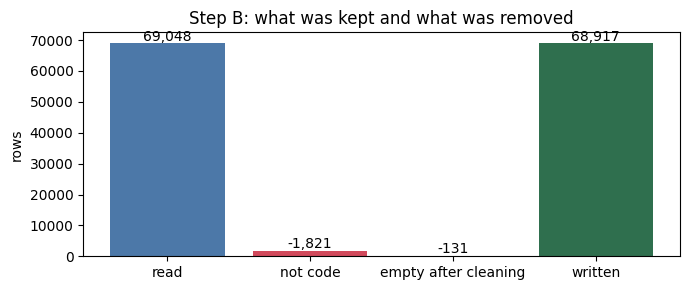

In [8]:
import matplotlib.pyplot as plt
steps = [('read', report_b['rows_read']), ('not code', -report_b['rows_dropped_not_code_target']),
         ('empty after cleaning', -report_b['rows_dropped_code_empty']), ('written', report_b['rows_written'])]
fig, ax = plt.subplots(figsize=(7, 3))
colors = ['#4c78a8', '#d1495b', '#d1495b', '#2f6f4e']
ax.bar([s[0] for s in steps], [abs(s[1]) for s in steps], color=colors)
for i, s in enumerate(steps): ax.text(i, abs(s[1]) + 800, f'{s[1]:,}', ha='center')
ax.set_ylabel('rows'); ax.set_title('Step B: what was kept and what was removed'); plt.tight_layout(); plt.show()

### Check the final file (in the temporary folder)

The table counts, for each project, the rows of the final CSV and the true links among them. This is what the evaluation tables use.

In [9]:
from collections import Counter
total, pos = Counter(), Counter()
with open(b_path, encoding='utf-8') as fh:
    for r in csv.DictReader(fh):
        total[r['project']] += 1; pos[r['project']] += int(r['gold'])
print(f"{'project':9s}{'rows':>8s}{'true':>8s}")
for p in total: print(f"{p:9s}{total[p]:8d}{pos[p]:8d}")
print(f"{'TOTAL':9s}{sum(total.values()):8d}{sum(pos.values()):8d}")

project      rows    true
eanci        2145     567
ebt          2050      98
etour        6728     308
itrust      50566     399
libest        728     204
smos         6700    1044
TOTAL       68917    2620


## Remember

* **Input:** `data/processed/` (7 projects) → **Output:** `data/final/all_projects_clean.csv` (68,917 pairs, 2,620 true links).
* Every rule is checked by small tests (`tests/test_build_gold_pairs.py`).
* Running the build again gives the same file. To check this, run `.venv/bin/python scripts/build_gold_pairs.py --check`.
* Folders such as `data/processed/petclinic` have no answer key (`gold.json`). They are skipped automatically.